# ***PART A — TABULAR DATA Pima Indians Diabetes Dataset***

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(url, names=columns)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nFirst 5 rows:")
display(df.head())

Shape: (768, 9)

Columns:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nZero Values:")
print((df == 0).sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero Values:
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [4]:
columns_to_replace = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[columns_to_replace] = df[columns_to_replace].replace(0, np.nan)

# Fill missing values with median
for column in columns_to_replace:
    df[column] = df[column].fillna(df[column].median())

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


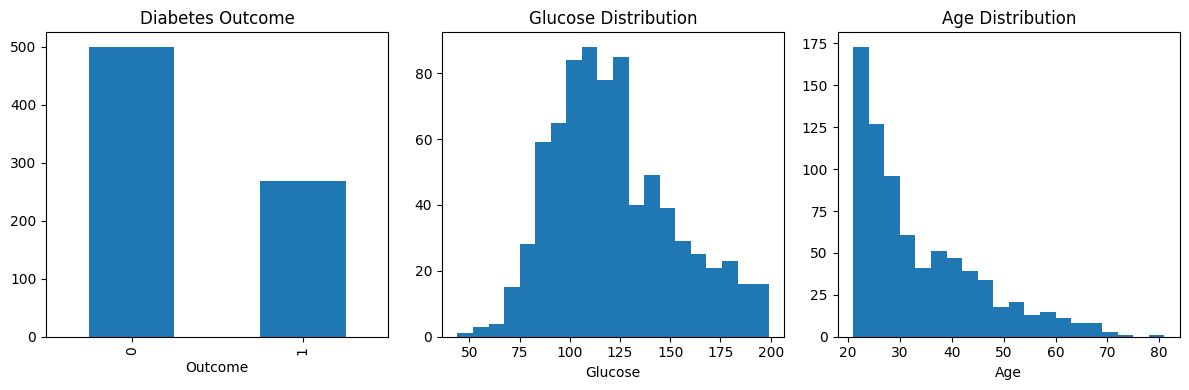

In [5]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
df["Outcome"].value_counts().plot(kind="bar")
plt.title("Diabetes Outcome")

plt.subplot(1, 3, 2)
plt.hist(df["Glucose"], bins=20)
plt.title("Glucose Distribution")
plt.xlabel("Glucose")

plt.subplot(1, 3, 3)
plt.hist(df["Age"], bins=20)
plt.title("Age Distribution")
plt.xlabel("Age")

plt.tight_layout()
plt.show()

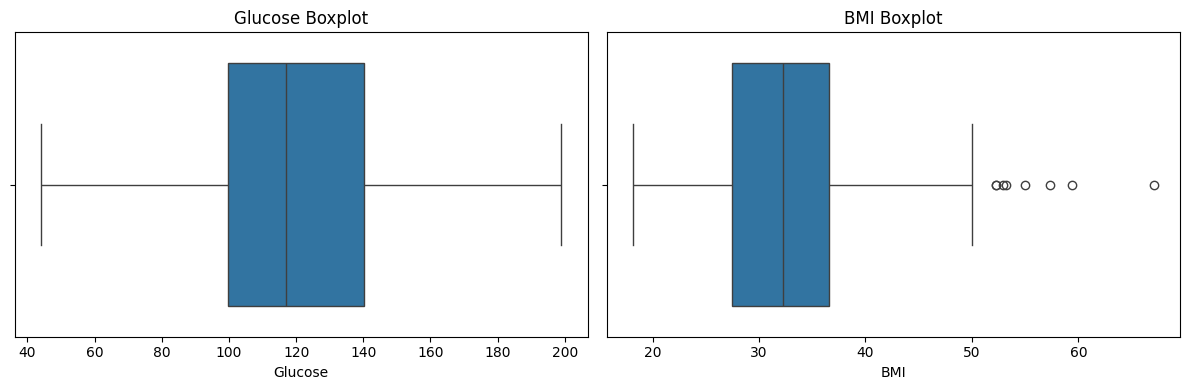

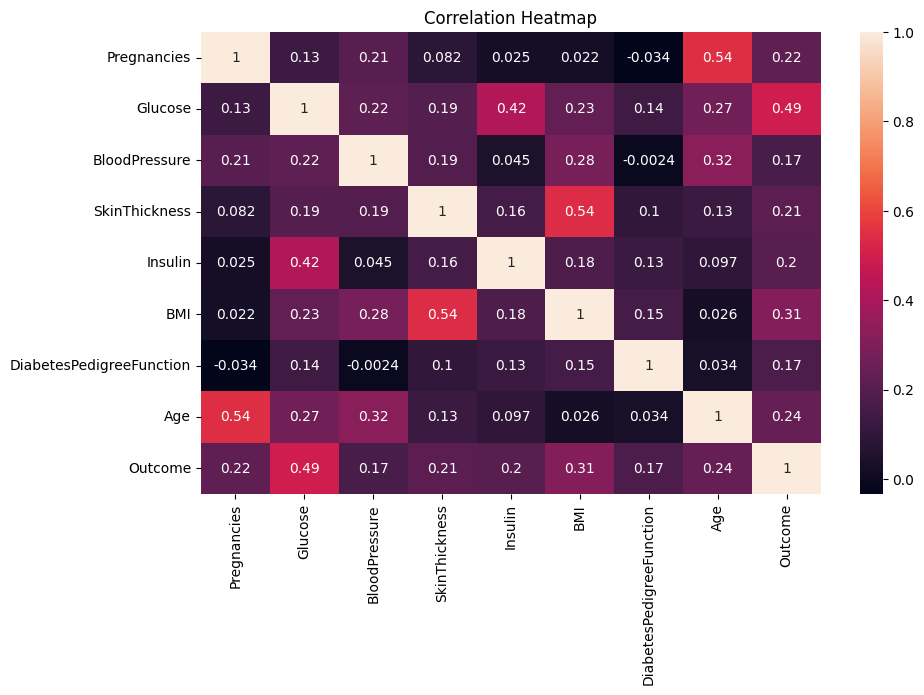

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df["Glucose"])
plt.title("Glucose Boxplot")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["BMI"])
plt.title("BMI Boxplot")

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()

In [7]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 40, 60, 100],
    labels=["Below 40", "40-60", "Above 60"]
)

print(df["AgeGroup"].value_counts())

display(pd.crosstab(df["AgeGroup"], df["Outcome"]))

AgeGroup
Below 40    574
40-60       167
Above 60     27
Name: count, dtype: int64


Outcome,0,1
AgeGroup,,
Below 40,408,166
40-60,72,95
Above 60,20,7


In [8]:
from scipy.stats import ttest_ind

diabetic = df[df["Outcome"] == 1]["Glucose"]
non_diabetic = df[df["Outcome"] == 0]["Glucose"]

print("Mean glucose - Diabetic:", diabetic.mean())
print("Mean glucose - Non-diabetic:", non_diabetic.mean())

t_stat, p_value = ttest_ind(diabetic, non_diabetic)

print("\nT-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a significant difference in glucose levels.")
else:
    print("There is no significant difference in glucose levels.")

Mean glucose - Diabetic: 142.13059701492537
Mean glucose - Non-diabetic: 110.682

T-statistic: 15.673795182294105
P-value: 3.1287190418423694e-48
There is a significant difference in glucose levels.


In [9]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["AgeGroup"], df["Outcome"])

chi2, p_value, dof, expected = chi2_contingency(table)

print("Contingency Table:")
display(table)

print("Chi-square value:", chi2)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a significant association between Age Group and Outcome.")
else:
    print("There is no significant association between Age Group and Outcome.")

Contingency Table:


Outcome,0,1
AgeGroup,,
Below 40,408,166
40-60,72,95
Above 60,20,7


Chi-square value: 45.52590124467898
P-value: 1.3006970428793555e-10
There is a significant association between Age Group and Outcome.


In [10]:
from scipy.stats import f_oneway

group1 = df[df["AgeGroup"] == "Below 40"]["Glucose"]
group2 = df[df["AgeGroup"] == "40-60"]["Glucose"]
group3 = df[df["AgeGroup"] == "Above 60"]["Glucose"]

f_stat, p_value = f_oneway(group1, group2, group3)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a significant difference between the group means.")
else:
    print("There is no significant difference between the group means.")

F-statistic: 14.996692346907592
P-value: 4.0874695373665573e-07
There is a significant difference between the group means.


In [11]:
features = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age"
]

X = df[features]
y = df["Outcome"]

print("Correlation with Outcome:")
print(df.corr(numeric_only=True)["Outcome"].sort_values(ascending=False))

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nScaled data shape:", X_scaled.shape)

Correlation with Outcome:
Outcome                     1.000000
Glucose                     0.492782
BMI                         0.312038
Age                         0.238356
Pregnancies                 0.221898
SkinThickness               0.214873
Insulin                     0.203790
DiabetesPedigreeFunction    0.173844
BloodPressure               0.165723
Name: Outcome, dtype: float64

Scaled data shape: (768, 8)


# ***PART B — TEXTUAL DATA Dataset: MTSamples Medical Transcriptions***

In [19]:
from google.colab import files
import pandas as pd

# Upload the CSV file
uploaded = files.upload()

# Get the actual uploaded filename automatically
filename = list(uploaded.keys())[0]

# Read the CSV file
text_df = pd.read_csv(
    filename,
    encoding="latin1",
    on_bad_lines="skip"
)

print("Dataset Shape:", text_df.shape)

print("\nColumn Names:")
print(text_df.columns)

print("\nFirst 5 Rows:")
display(text_df.head())

Saving mtsamples.csv to mtsamples (2).csv
Dataset Shape: (4999, 6)

Column Names:
Index(['Unnamed: 0', 'description', 'medical_specialty', 'sample_name',
       'transcription', 'keywords'],
      dtype='object')

First 5 Rows:


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [20]:
text_df["clean_text"] = text_df["transcription"].str.lower()

# Remove special characters
text_df["clean_text"] = text_df["clean_text"].apply(
    lambda x: re.sub(r"[^a-zA-Z\s]", "", str(x))
)

# Remove extra spaces
text_df["clean_text"] = text_df["clean_text"].str.replace(
    r"\s+", " ", regex=True
)

# Count words
text_df["word_count"] = text_df["clean_text"].apply(
    lambda x: len(x.split())
)

# Tokenization
text_df["tokens"] = text_df["clean_text"].apply(
    lambda x: x.split()
)

display(text_df[["transcription", "clean_text", "word_count", "tokens"]].head())

,transcription,clean_text,word_count,tokens
0,"SUBJECTIVE:, This 23-year-old white female pr...",subjective this yearold white female presents ...,201,"[subjective, this, yearold, white, female, pre..."
1,"PAST MEDICAL HISTORY:, He has difficulty climb...",past medical history he has difficulty climbin...,343,"[past, medical, history, he, has, difficulty, ..."
2,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...",history of present illness i have seen abc tod...,691,"[history, of, present, illness, i, have, seen,..."
3,"2-D M-MODE: , ,1. Left atrial enlargement wit...",d mmode left atrial enlargement with left atri...,61,"[d, mmode, left, atrial, enlargement, with, le..."
4,1. The left ventricular cavity size and wall ...,the left ventricular cavity size and wall thi...,221,"[the, left, ventricular, cavity, size, and, wa..."


Average number of words: 448.2260452090418


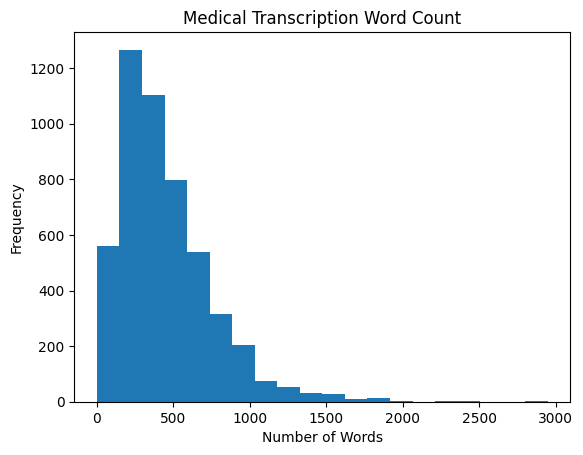

In [21]:
print("Average number of words:",
      text_df["word_count"].mean())

plt.hist(text_df["word_count"], bins=20)

plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Medical Transcription Word Count")

plt.show()

# ***PART C — IMAGE DATA Dataset: Chest X-Ray Images (Pneumonia).***

In [23]:
!pip install -q kagglehub


In [24]:
import kagglehub

# Download the dataset from Kaggle
path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded to: /kaggle/input/chest-xray-pneumonia


In [25]:
import os

print("Files/Folders:")
print(os.listdir(path))

Files/Folders:
['chest_xray']


In [26]:
# Find the chest_xray folder
data_path = os.path.join(path, "chest_xray")

print("\nFolders inside chest_xray:")
print(os.listdir(data_path))


Folders inside chest_xray:
['chest_xray', '__MACOSX', 'val', 'test', 'train']


In [27]:
# Check classes
for folder in ["train", "test", "val"]:
    folder_path = os.path.join(data_path, folder)

    print("\n", folder)
    print(os.listdir(folder_path))


 train
['PNEUMONIA', 'NORMAL']

 test
['PNEUMONIA', 'NORMAL']

 val
['PNEUMONIA', 'NORMAL']


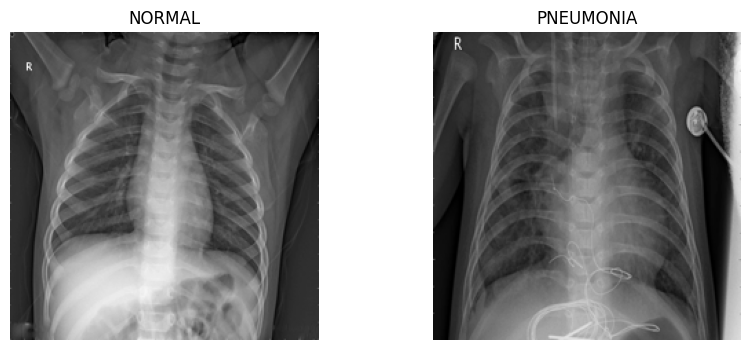

Normal image shape: (224, 224)
Pneumonia image shape: (224, 224)
Pixel value range: 0.0 to 0.7176470588235294


In [29]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Select one NORMAL and one PNEUMONIA image
normal_path = os.path.join(data_path, "train", "NORMAL")
pneumonia_path = os.path.join(data_path, "train", "PNEUMONIA")

normal_image = os.path.join(normal_path, os.listdir(normal_path)[0])
pneumonia_image = os.path.join(pneumonia_path, os.listdir(pneumonia_path)[0])

# Load images
normal = Image.open(normal_image).convert("L")
pneumonia = Image.open(pneumonia_image).convert("L")

# Resize images
normal_resized = normal.resize((224, 224))
pneumonia_resized = pneumonia.resize((224, 224))

# Convert to NumPy arrays and normalize pixel values
normal_array = np.array(normal_resized) / 255.0
pneumonia_array = np.array(pneumonia_resized) / 255.0

# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(normal_array, cmap="gray")
plt.title("NORMAL")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(pneumonia_array, cmap="gray")
plt.title("PNEUMONIA")
plt.axis("off")

plt.show()

print("Normal image shape:", normal_array.shape)
print("Pneumonia image shape:", pneumonia_array.shape)
print("Pixel value range:", normal_array.min(), "to", normal_array.max())

# ***PART 4***

In [30]:
# Install WFDB
!pip install -q wfdb

import wfdb
import matplotlib.pyplot as plt

# Download MIT-BIH Arrhythmia Database
record = wfdb.rdrecord(
    "100",
    pn_dir="mitdb"
)

print("Sampling frequency:", record.fs)
print("Number of samples:", record.sig_len)
print("Number of signals:", record.n_sig)
print("Signal names:", record.sig_name)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 9.2 MB/s eta 0:00:00
Sampling frequency: 360
Number of samples: 650000
Number of signals: 2
Signal names: ['MLII', 'V5']


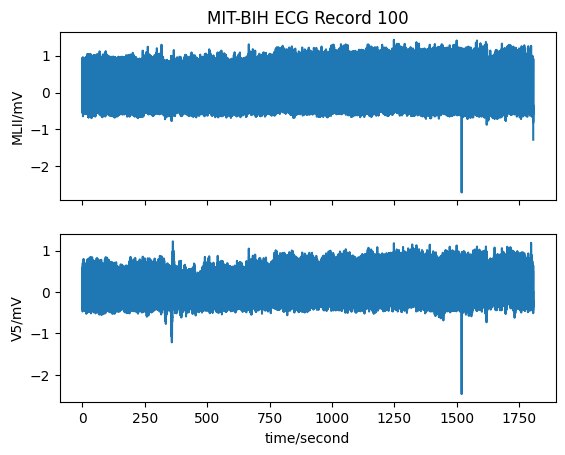

In [31]:
# Display first 10 seconds of ECG
wfdb.plot_wfdb(
    record=record,
    title="MIT-BIH ECG Record 100"
)

plt.show()

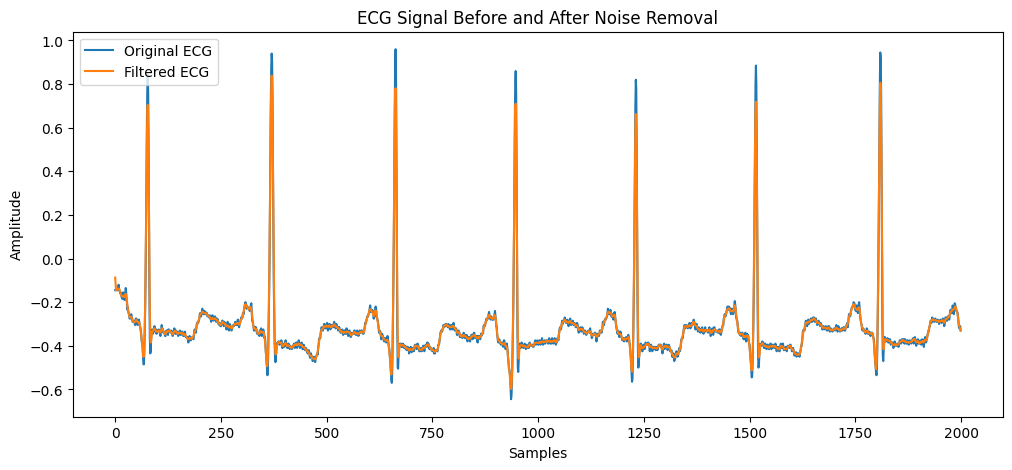

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Get ECG signal
ecg_signal = record.p_signal[:, 0]

# Moving average filter
window_size = 5

filtered_signal = np.convolve(
    ecg_signal,
    np.ones(window_size) / window_size,
    mode="same"
)

# Display original and filtered ECG
plt.figure(figsize=(12, 5))

plt.plot(ecg_signal[:2000], label="Original ECG")
plt.plot(filtered_signal[:2000], label="Filtered ECG")

plt.title("ECG Signal Before and After Noise Removal")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.legend()
plt.show()

In [33]:
# Create signal windows
window_size = 500

windows = []

for i in range(0, len(filtered_signal) - window_size, window_size):
    window = filtered_signal[i:i + window_size]
    windows.append(window)

windows = np.array(windows)

print("Number of windows:", len(windows))
print("Window shape:", windows.shape)

Number of windows: 1299
Window shape: (1299, 500)


In [34]:
# Extract simple features from each ECG window

mean_values = np.mean(windows, axis=1)
std_values = np.std(windows, axis=1)
max_values = np.max(windows, axis=1)
min_values = np.min(windows, axis=1)

features = np.column_stack([
    mean_values,
    std_values,
    max_values,
    min_values
])

print("Feature matrix shape:", features.shape)

print("\nFirst 5 feature rows:")
print(features[:5])

Feature matrix shape: (1299, 4)

First 5 feature rows:
[[-0.292798    0.17444434  0.839      -0.494     ]
 [-0.330814    0.16257354  0.781      -0.598     ]
 [-0.331836    0.11053999  0.663      -0.519     ]
 [-0.31522     0.16602107  0.806      -0.513     ]
 [-0.345378    0.16958967  0.759      -0.54      ]]
